# De quoi parle le pape François selon les pays ?

*Ce projet est réalisé dans le cadre du cours de Python pour la Data Science donné par Lino Galiana à l'ENSAE Paris en 2026.*

### Objectif et méthodologie

L'objectif est de regarder de quoi parle le pape François dans ses discours, et si cela change selon le pays où il se trouve.

Le projet est organisé en deux parties :
  1) Récupération des données
  2) Étude descriptive

Les fonctions utilisées sont dans le dossier `analyse_discours/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path().resolve() / "analyse_discours"))

from compter_mots import DOSSIER_RESULTATS, compter_mots, lire_discours
from garder_noms_adjectifs import compter_noms_adjectifs
from themes import THEMES, compter_mots_des_themes
from chercher_mot import charger_discours
from statistiques import preparer_discours, stats_globales, stats_par_pays

DOSSIER_RESULTATS.mkdir(exist_ok=True)

## 1) Récupération des données

### Récupération des discours

Les discours du pape sont disponibles sur le site du Vatican. Pour chaque année il y a une page qui liste les discours, par exemple [https://www.vatican.va/content/francesco/fr/speeches/2016.index.html](https://www.vatican.va/content/francesco/fr/speeches/2016.index.html).

Nous avons fait un algorithme de scraping qui parcourt ces pages de 2013 à 2025 et enregistre chaque discours dans le dossier `corpus_francois/`.

*⚠️ Le scraping est très long, on ne le relance pas ici : on lit directement les fichiers enregistrés.*

In [2]:
textes = lire_discours()
print(len(textes), "discours")

1742 discours


### Nettoyage des données

Si on regarde les 30 mots qui reviennent le plus, on obtient ce résultat :

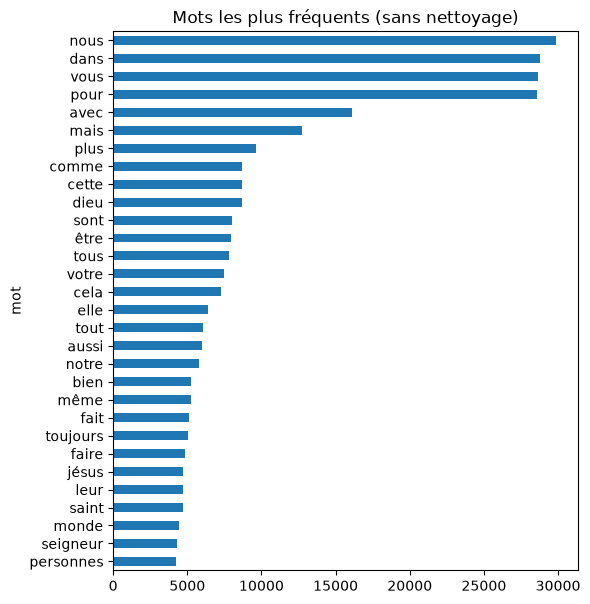

In [3]:
frequences = compter_mots(textes, longueur_min=4)
frequences.head(30).plot.barh(x="mot", y="occurrences", figsize=(6, 7), legend=False)
plt.gca().invert_yaxis()
plt.title("Mots les plus fréquents (sans nettoyage)")
plt.show()

On voit qu'il faut enlever tous les mots qui n'ont pas de sens (« nous », « dans », « pour »...). On utilise spaCy pour ne garder que les noms et les adjectifs. Cette étape prend quelques minutes, le résultat est stocké dans un fichier csv.

  100 discours analysés


  200 discours analysés


  300 discours analysés


  400 discours analysés


  500 discours analysés


  600 discours analysés


... (7 outputs left out)

  1400 discours analysés


  1500 discours analysés


  1600 discours analysés


  1700 discours analysés


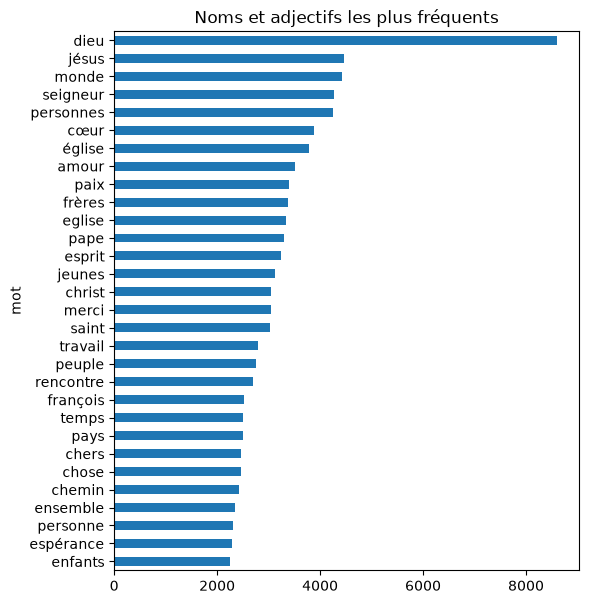

In [4]:
noms_adjectifs = compter_noms_adjectifs(textes, longueur_min=4)
noms_adjectifs.to_csv(DOSSIER_RESULTATS / "noms_adjectifs.csv", index=False, encoding="utf-8-sig")

noms_adjectifs.head(30).plot.barh(x="mot", y="occurrences", figsize=(6, 7), legend=False)
plt.gca().invert_yaxis()
plt.title("Noms et adjectifs les plus fréquents")
plt.show()

C'est plus intéressant : à côté du vocabulaire religieux (« dieu », « jésus », « église ») on voit « monde », « paix » ou « jeunes ». On remarque que « église » et « eglise » sont comptés à part, à cause des majuscules sans accent sur le site.

## 2) Étude descriptive

### Les thèmes

À partir de ces mots, nous avons fait 12 thèmes à la main (paix et guerre, migrations, écologie, famille...). Un thème est juste une liste de mots, dans `analyse_discours/themes.py`.

On peut aussi vérifier dans quel contexte un mot est employé avec la fenêtre `python analyse_discours/chercher_mot.py`.

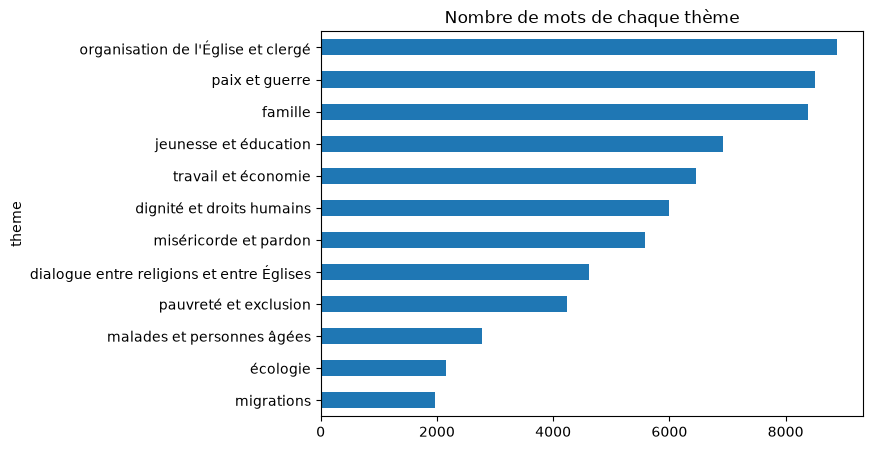

In [5]:
mots_par_theme = compter_mots_des_themes(textes)
mots_par_theme.groupby("theme")["occurrences"].sum().sort_values().plot.barh(figsize=(7, 5))
plt.title("Nombre de mots de chaque thème")
plt.show()

### Les thèmes selon les pays

Chaque discours est rattaché à un pays grâce au lieu écrit au début du texte (`analyse_discours/pays.py`).

In [6]:
discours = preparer_discours(charger_discours())
pd.Series([d["pays"] for d in discours]).value_counts().head(10)

Vatican / Rome    1279
Italie              63
Avion               56
Brésil              16
États-Unis          14
Pologne             12
Portugal            10
Mexique              9
Israël               8
Colombie             8
Name: count, dtype: int64

La plupart des discours sont au Vatican. Si on compte juste les mots, le Vatican est donc toujours premier. Il faut normaliser par le nombre de mots prononcés dans chaque pays. Exemple avec les migrations (pays avec au moins 3 discours) :

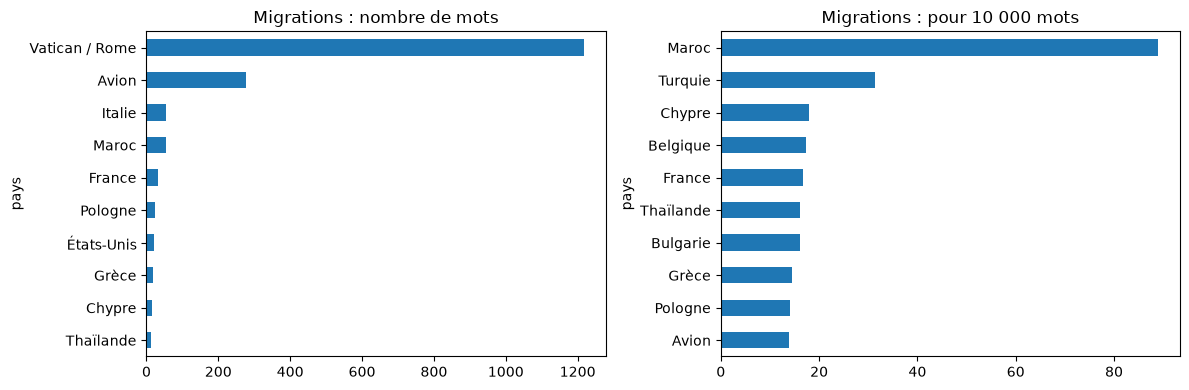

In [7]:
stats = stats_par_pays(THEMES["migrations"], discours)
stats = stats[stats["discours"] >= 3]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.sort_values("occurrences").tail(10).plot.barh(x="pays", y="occurrences", ax=axes[0], legend=False)
axes[0].set_title("Migrations : nombre de mots")
stats.sort_values("pour_10000_mots").tail(10).plot.barh(x="pays", y="pour_10000_mots", ax=axes[1], legend=False)
axes[1].set_title("Migrations : pour 10 000 mots")
plt.tight_layout()
plt.show()

Une fois normalisé, ce n'est plus le Vatican qui parle le plus de migrations, mais des pays comme le Maroc, Chypre ou la France.

On fait la même chose pour tous les thèmes. On divise la fréquence du thème dans le pays par sa fréquence moyenne : au-dessus de 1, le pape en parle plus que d'habitude dans ce pays. Voici les 3 pays où chaque thème est le plus présent :

In [8]:
lignes = []
for theme, mots in THEMES.items():
    moyenne = stats_globales(mots, discours)["pour_10000_mots"]
    stats = stats_par_pays(mots, discours)
    stats = stats[stats["discours"] >= 3]
    for _, ligne in stats.iterrows():
        lignes.append({"theme": theme, "pays": ligne["pays"],
                       "indice": round(ligne["pour_10000_mots"] / moyenne, 2)})

indices = pd.DataFrame(lignes)
indices.sort_values("indice", ascending=False).groupby("theme").head(3).sort_values(["theme", "indice"], ascending=[True, False])

,theme,pays,indice
295,dialogue entre religions et entre Églises,Turquie,5.51
296,dialogue entre religions et entre Églises,Israël,5.26
297,dialogue entre religions et entre Églises,Bosnie-Herzégovine,4.43
354,dignité et droits humains,Maroc,2.96
355,dignité et droits humains,Turquie,2.79
356,dignité et droits humains,États-Unis,2.66
0,famille,Irlande,6.33
1,famille,Philippines,4.08
2,famille,Cuba,2.84
177,jeunesse et éducation,Timor oriental,3.69


Certains résultats sont attendus : la paix et la guerre ressortent au Sri Lanka, en Turquie ou en Centrafrique, le dialogue entre religions en Turquie et en Israël, la famille en Irlande (rencontre mondiale des familles de 2018). Mais beaucoup de pays n'ont que 3 ou 4 discours, donc un seul discours peut suffire à mettre un pays en tête.

## Conclusion

Ce projet nous a permis de découvrir le scraping et quelques méthodes de traitement de texte. On voit que le pape adapte un peu ses thèmes au pays visité, surtout pour la paix et le dialogue entre religions dans les pays en conflit.

Pour aller plus loin, on pourrait trouver les thèmes automatiquement (word embedding, LDA), tenir compte du public (évêques, jeunes, autorités) ou comparer avec les papes précédents.